In [ ]:
# ================================================================
# PHASE 4D — CELL 1
# SETUP
# ================================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import json

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


print("=" * 80)
print("PHASE 4D — REPRESENTATIVE FAILURE CASE ANALYSIS")
print("=" * 80)

print("""
Purpose:
Perform reproducible patient-level inspection of representative
success and failure modes from the frozen LV analysis pipeline.

Protocol:
• Frozen pipeline only
• No model retraining
• No threshold tuning
• No case selection based on visual appearance
• Case-selection criteria are defined quantitatively
• Images are inspected only AFTER cases are selected
• Examples are illustrative, not population-level evidence
""")

Mounted at /content/drive
PHASE 4D — REPRESENTATIVE FAILURE CASE ANALYSIS

Purpose:
Perform reproducible patient-level inspection of representative
success and failure modes from the frozen LV analysis pipeline.

Protocol:
• Frozen pipeline only
• No model retraining
• No threshold tuning
• No case selection based on visual appearance
• Case-selection criteria are defined quantitatively
• Images are inspected only AFTER cases are selected
• Examples are illustrative, not population-level evidence



In [ ]:
# ================================================================
# PHASE 4D — CELL 2
# PATHS
# ================================================================

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/CAMUS_FINAL"
)

PHASE4_ROOT = (
    PROJECT_ROOT
    / "phase4_robustness"
)

PHASE4A_DIR = (
    PHASE4_ROOT
    / "phase4A_error_propagation"
)

PHASE4B_DIR = (
    PHASE4_ROOT
    / "phase4B_confidence_uncertainty"
)

PHASE4C_DIR = (
    PHASE4_ROOT
    / "phase4C_image_quality_subgroups"
)

PHASE4D_DIR = (
    PHASE4_ROOT
    / "phase4D_representative_failure_cases"
)

PHASE4D_TABLES_DIR = (
    PHASE4D_DIR
    / "tables"
)

PHASE4D_FIGURES_DIR = (
    PHASE4D_DIR
    / "figures"
)

PHASE4D_CONFIGS_DIR = (
    PHASE4D_DIR
    / "configs"
)


for directory in [
    PHASE4D_DIR,
    PHASE4D_TABLES_DIR,
    PHASE4D_FIGURES_DIR,
    PHASE4D_CONFIGS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


print("Phase 4D:")
print(PHASE4D_DIR)

print(
    "\n✓ Phase 4D directories ready."
)

Phase 4D:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4D_representative_failure_cases

✓ Phase 4D directories ready.


In [ ]:
# ================================================================
# PHASE 4D — CELL 3
# VERIFY PREVIOUS PHASES
# ================================================================

completion_paths = {

    "Phase 4A":
        PHASE4A_DIR
        / "PHASE4A_COMPLETE.json",

    "Phase 4B":
        PHASE4B_DIR
        / "PHASE4B_COMPLETE.json",

    "Phase 4C":
        PHASE4C_DIR
        / "PHASE4C_COMPLETE.json"
}


print("=" * 80)
print("PREVIOUS PHASE STATUS")
print("=" * 80)


for phase_name, path in completion_paths.items():

    assert path.exists(), (
        f"{phase_name} completion marker missing."
    )

    with open(
        path,
        "r"
    ) as file:

        record = json.load(file)


    assert (
        record["status"]
        == "COMPLETE_AND_FROZEN"
    )


    print(
        f"✓ {phase_name}: COMPLETE_AND_FROZEN"
    )


print(
    "\n✓ Phase 4D can proceed."
)

PREVIOUS PHASE STATUS
✓ Phase 4A: COMPLETE_AND_FROZEN
✓ Phase 4B: COMPLETE_AND_FROZEN
✓ Phase 4C: COMPLETE_AND_FROZEN

✓ Phase 4D can proceed.


In [ ]:
# ================================================================
# PHASE 4D — CELL 4
# LOAD FROZEN PATIENT-LEVEL ANALYSIS
# ================================================================

PHASE4C_CANONICAL_PATH = (
    PHASE4C_DIR
    / "tables"
    / "phase4C_canonical_image_quality_analysis.csv"
)


assert PHASE4C_CANONICAL_PATH.exists()


phase4D_df = pd.read_csv(
    PHASE4C_CANONICAL_PATH
)


assert len(phase4D_df) == 50

assert (
    phase4D_df[
        "patient_id"
    ].nunique()
    == 50
)


print("=" * 80)
print("FROZEN PATIENT TABLE LOADED")
print("=" * 80)

print(
    "\nShape:",
    phase4D_df.shape
)

print(
    "Patients:",
    phase4D_df[
        "patient_id"
    ].nunique()
)

print(
    "\n✓ Frozen patient-level data ready."
)

FROZEN PATIENT TABLE LOADED

Shape: (50, 64)
Patients: 50

✓ Frozen patient-level data ready.


In [ ]:
# ================================================================
# PHASE 4D — CELL 5
# VERIFY CASE-SELECTION VARIABLES
# ================================================================

required_columns = [

    "patient_id",

    "reference_EF_pct",
    "GT_EF_pct",
    "PRED_EF_pct",

    "reference_EF_class",
    "learned_prediction",

    "classification_error",

    "ED_dice",
    "ES_dice",

    "ED_area_abs_relative_error_pct",
    "ES_area_abs_relative_error_pct",

    "EDV_abs_error_ml",
    "ESV_abs_error_ml",

    "segmentation_induced_EF_abs_error_pp",
    "end_to_end_EF_abs_error_pp",

    "model_confidence",
    "confidence_margin",
    "normalized_entropy",

    "image_quality"
]


missing_columns = [

    column
    for column in required_columns

    if column not in phase4D_df.columns
]


assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)


print(
    "✓ All case-selection variables available."
)

✓ All case-selection variables available.


In [ ]:
# ================================================================
# PHASE 4D — CELL 6
# EF-BOUNDARY DISTANCE
# ================================================================

phase4D_df = phase4D_df.copy()


phase4D_df[
    "distance_to_nearest_EF_boundary_pp"
] = np.minimum(

    np.abs(
        phase4D_df[
            "reference_EF_pct"
        ] - 40
    ),

    np.abs(
        phase4D_df[
            "reference_EF_pct"
        ] - 50
    )
)


print("=" * 80)
print("EF BOUNDARY DISTANCE")
print("=" * 80)

display(

    phase4D_df[[
        "patient_id",
        "reference_EF_pct",
        "reference_EF_class",
        "distance_to_nearest_EF_boundary_pp"
    ]]
    .sort_values(
        "distance_to_nearest_EF_boundary_pp"
    )
    .head(10)
)

EF BOUNDARY DISTANCE


,patient_id,reference_EF_pct,reference_EF_class,distance_to_nearest_EF_boundary_pp
3,patient0016,50.0,Higher_EF,0.0
2,patient0014,50.0,Higher_EF,0.0
28,patient0288,50.0,Higher_EF,0.0
29,patient0302,49.0,Intermediate_EF,1.0
48,patient0487,41.0,Intermediate_EF,1.0
38,patient0378,49.0,Intermediate_EF,1.0
20,patient0143,52.0,Higher_EF,2.0
18,patient0126,38.0,Lower_EF,2.0
23,patient0215,52.0,Higher_EF,2.0
44,patient0446,48.0,Intermediate_EF,2.0


In [ ]:
# ================================================================
# PHASE 4D — CELL 7
# PREDEFINED REPRESENTATIVE CASE SELECTION
# ================================================================

# ---------------------------------------------------------------
# A — Largest segmentation-induced EF error
# ---------------------------------------------------------------

case_A = (
    phase4D_df
    .sort_values(
        [
            "segmentation_induced_EF_abs_error_pp",
            "patient_id"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


# ---------------------------------------------------------------
# B — Most confident misclassification
# ---------------------------------------------------------------

misclassified_df = phase4D_df[
    phase4D_df[
        "classification_error"
    ] == 1
]


assert len(misclassified_df) > 0


case_B = (
    misclassified_df
    .sort_values(
        [
            "model_confidence",
            "patient_id"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


# ---------------------------------------------------------------
# C — Largest end-to-end EF error
# ---------------------------------------------------------------

case_C = (
    phase4D_df
    .sort_values(
        [
            "end_to_end_EF_abs_error_pp",
            "patient_id"
        ],
        ascending=[
            False,
            True
        ]
    )
    .iloc[0]
)


# ---------------------------------------------------------------
# D — Misclassification nearest an EF boundary
# ---------------------------------------------------------------

case_D = (
    misclassified_df
    .sort_values(
        [
            "distance_to_nearest_EF_boundary_pp",
            "end_to_end_EF_abs_error_pp",
            "patient_id"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .iloc[0]
)


# ---------------------------------------------------------------
# E — Representative successful case
# ---------------------------------------------------------------

successful_df = phase4D_df[
    phase4D_df[
        "classification_error"
    ] == 0
].copy()


successful_df[
    "mean_ED_ES_dice_for_selection"
] = (

    successful_df[
        "ED_dice"
    ]

    +

    successful_df[
        "ES_dice"
    ]

) / 2


successful_df[
    "dice_rank"
] = (
    successful_df[
        "mean_ED_ES_dice_for_selection"
    ]
    .rank(
        ascending=False,
        method="average"
    )
)


successful_df[
    "seg_EF_error_rank"
] = (
    successful_df[
        "segmentation_induced_EF_abs_error_pp"
    ]
    .rank(
        ascending=True,
        method="average"
    )
)


successful_df[
    "end_to_end_error_rank"
] = (
    successful_df[
        "end_to_end_EF_abs_error_pp"
    ]
    .rank(
        ascending=True,
        method="average"
    )
)


successful_df[
    "success_combined_rank"
] = (

    successful_df[
        "dice_rank"
    ]

    +

    successful_df[
        "seg_EF_error_rank"
    ]

    +

    successful_df[
        "end_to_end_error_rank"
    ]
)


case_E = (
    successful_df
    .sort_values(
        [
            "success_combined_rank",
            "patient_id"
        ]
    )
    .iloc[0]
)


print(
    "✓ Five predefined selection criteria applied."
)

✓ Five predefined selection criteria applied.


In [ ]:
# ================================================================
# PHASE 4D — CELL 8
# REPRESENTATIVE CASE TABLE
# ================================================================

selected_cases = [

    (
        "A",
        "Largest segmentation-induced EF error",
        case_A
    ),

    (
        "B",
        "Most confident misclassification",
        case_B
    ),

    (
        "C",
        "Largest end-to-end EF error",
        case_C
    ),

    (
        "D",
        "Misclassification nearest EF boundary",
        case_D
    ),

    (
        "E",
        "Representative successful case",
        case_E
    )
]


selection_records = []


for case_label, criterion, row in selected_cases:

    selection_records.append({

        "case_label":
            case_label,

        "selection_criterion":
            criterion,

        "patient_id":
            row["patient_id"],

        "image_quality":
            row["image_quality"],

        "reference_EF_pct":
            row["reference_EF_pct"],

        "GT_EF_pct":
            row["GT_EF_pct"],

        "PRED_EF_pct":
            row["PRED_EF_pct"],

        "reference_class":
            row["reference_EF_class"],

        "predicted_class":
            row["learned_prediction"],

        "classification_error":
            int(
                row[
                    "classification_error"
                ]
            ),

        "ED_dice":
            row["ED_dice"],

        "ES_dice":
            row["ES_dice"],

        "segmentation_EF_error_pp":
            row[
                "segmentation_induced_EF_abs_error_pp"
            ],

        "end_to_end_EF_error_pp":
            row[
                "end_to_end_EF_abs_error_pp"
            ],

        "model_confidence":
            row["model_confidence"],

        "confidence_margin":
            row["confidence_margin"],

        "normalized_entropy":
            row["normalized_entropy"],

        "boundary_distance_pp":
            row[
                "distance_to_nearest_EF_boundary_pp"
            ]
    })


phase4D_selection_df = pd.DataFrame(
    selection_records
)


print("=" * 120)
print("PHASE 4D — PREDEFINED REPRESENTATIVE CASES")
print("=" * 120)


display(
    phase4D_selection_df.round(4)
)


unique_patients = (
    phase4D_selection_df[
        "patient_id"
    ].nunique()
)


print(
    f"\nCriteria selected {unique_patients} "
    f"unique patient(s) across 5 case definitions."
)


if unique_patients < 5:

    print(
        "\nNOTE: Some criteria selected the same patient."
    )

    print(
        "This overlap is retained because cases were selected "
        "by predefined quantitative criteria rather than "
        "manually replaced."
    )

PHASE 4D — PREDEFINED REPRESENTATIVE CASES


,case_label,selection_criterion,patient_id,image_quality,reference_EF_pct,GT_EF_pct,PRED_EF_pct,reference_class,predicted_class,classification_error,ED_dice,ES_dice,segmentation_EF_error_pp,end_to_end_EF_error_pp,model_confidence,confidence_margin,normalized_entropy,boundary_distance_pp
0,A,Largest segmentation-induced EF error,patient0358,Poor,44.0,47.4914,29.4360,Intermediate_EF,Lower_EF,1,0.9104,0.9440,18.0554,14.5640,0.8882,0.7776,0.3250,4.0
1,B,Most confident misclassification,patient0358,Poor,44.0,47.4914,29.4360,Intermediate_EF,Lower_EF,1,0.9104,0.9440,18.0554,14.5640,0.8882,0.7776,0.3250,4.0
2,C,Largest end-to-end EF error,patient0217,Good,19.0,67.6727,61.7946,Lower_EF,Higher_EF,1,0.9550,0.8684,5.8781,42.7946,0.7888,0.5875,0.5055,21.0
3,D,Misclassification nearest EF boundary,patient0288,Medium,50.0,48.3000,48.2466,Higher_EF,Intermediate_EF,1,0.9076,0.8998,0.0534,1.7534,0.5786,0.3360,0.8811,0.0
4,E,Representative successful case,patient0230,Good,32.0,32.1646,33.6454,Lower_EF,Lower_EF,0,0.9673,0.9605,1.4807,1.6454,0.8243,0.6520,0.4380,8.0



Criteria selected 4 unique patient(s) across 5 case definitions.

NOTE: Some criteria selected the same patient.
This overlap is retained because cases were selected by predefined quantitative criteria rather than manually replaced.


In [ ]:
# ================================================================
# PHASE 4D — CELL 9
# FREEZE CASE SELECTION BEFORE IMAGE INSPECTION
# ================================================================

PHASE4D_SELECTION_PATH = (
    PHASE4D_TABLES_DIR
    / "phase4D_predefined_case_selection.csv"
)


phase4D_selection_df.to_csv(
    PHASE4D_SELECTION_PATH,
    index=False
)


selection_protocol = {

    "phase":
        "Phase 4D",

    "analysis":
        "Representative Failure Case Analysis",

    "selection_performed_before_image_inspection":
        True,

    "selection_rules": {

        "A":
            "Patient with largest segmentation-induced "
            "absolute EF error.",

        "B":
            "Misclassified patient with largest frozen "
            "classifier confidence score.",

        "C":
            "Patient with largest absolute end-to-end "
            "reference-to-predicted EF error.",

        "D":
            "Misclassified patient with smallest distance "
            "from reference EF to the nearest 40% or 50% "
            "classification boundary. Ties prioritized by "
            "larger end-to-end EF error, then patient ID.",

        "E":
            "Correctly classified patient minimizing the sum "
            "of ranks for high mean ED/ES Dice, low "
            "segmentation-induced EF error, and low "
            "end-to-end EF error."
    },

    "duplicate_policy":
        (
            "If multiple criteria select the same patient, "
            "the duplicate is retained and not manually "
            "replaced."
        ),

    "visual_cherry_picking":
        False
}


PHASE4D_SELECTION_PROTOCOL_PATH = (
    PHASE4D_CONFIGS_DIR
    / "phase4D_case_selection_protocol.json"
)


with open(
    PHASE4D_SELECTION_PROTOCOL_PATH,
    "w"
) as file:

    json.dump(
        selection_protocol,
        file,
        indent=4
    )


assert PHASE4D_SELECTION_PATH.exists()
assert PHASE4D_SELECTION_PROTOCOL_PATH.exists()


print("=" * 80)
print("CASE SELECTION FROZEN")
print("=" * 80)

print(
    "\nSelection table:",
    PHASE4D_SELECTION_PATH
)

print(
    "\nSelection protocol:",
    PHASE4D_SELECTION_PROTOCOL_PATH
)

print(
    "\n✓ Patient selection recorded before image inspection."
)

CASE SELECTION FROZEN

Selection table: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4D_representative_failure_cases/tables/phase4D_predefined_case_selection.csv

Selection protocol: /content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4D_representative_failure_cases/configs/phase4D_case_selection_protocol.json

✓ Patient selection recorded before image inspection.


In [ ]:
# ================================================================
# PHASE 4D — CELL 10
# RESTORE CAMUS DATASET IN FRESH COLAB RUNTIME
# ================================================================

from pathlib import Path
import zipfile
import shutil


# ---------------------------------------------------------------
# ESTABLISHED CAMUS ARCHIVE PATHS
# ---------------------------------------------------------------

OUTER_ZIP_PATH = Path(
    "/content/drive/MyDrive/download.zip"
)

OUTER_EXTRACT_DIR = Path(
    "/content/camus_data"
)

INNER_ARCHIVE_PATH = (
    OUTER_EXTRACT_DIR
    / "download"
)

INNER_EXTRACT_DIR = Path(
    "/content/camus_data_final"
)

DATASET_PATH = (
    INNER_EXTRACT_DIR
    / "database_nifti"
)


print("=" * 80)
print("RESTORING CAMUS DATASET")
print("=" * 80)


# ---------------------------------------------------------------
# STEP 1 — VERIFY OUTER ARCHIVE
# ---------------------------------------------------------------

assert OUTER_ZIP_PATH.exists(), (
    f"Outer CAMUS archive not found:\n{OUTER_ZIP_PATH}"
)

print(
    "\n✓ Outer archive found:"
)

print(
    OUTER_ZIP_PATH
)


# ---------------------------------------------------------------
# STEP 2 — EXTRACT OUTER ZIP IF NEEDED
# ---------------------------------------------------------------

if not INNER_ARCHIVE_PATH.exists():

    print(
        "\nExtracting outer archive..."
    )

    OUTER_EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with zipfile.ZipFile(
        OUTER_ZIP_PATH,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            OUTER_EXTRACT_DIR
        )

    print(
        "✓ Outer archive extracted."
    )

else:

    print(
        "\n✓ Outer archive already extracted."
    )


assert INNER_ARCHIVE_PATH.exists(), (
    f"Inner archive not found after outer extraction:\n"
    f"{INNER_ARCHIVE_PATH}"
)


print(
    "\n✓ Inner archive found:"
)

print(
    INNER_ARCHIVE_PATH
)


# ---------------------------------------------------------------
# STEP 3 — EXTRACT INNER ARCHIVE IF NEEDED
# ---------------------------------------------------------------

if not DATASET_PATH.exists():

    print(
        "\nExtracting inner CAMUS archive..."
    )

    INNER_EXTRACT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )


    # The inner file may not carry a normal .zip extension,
    # so shutil.unpack_archive may not recognize it.
    # We already know this CAMUS download is a ZIP-format archive.

    with zipfile.ZipFile(
        INNER_ARCHIVE_PATH,
        "r"
    ) as zip_ref:

        zip_ref.extractall(
            INNER_EXTRACT_DIR
        )

    print(
        "✓ Inner archive extracted."
    )

else:

    print(
        "\n✓ Inner CAMUS archive already extracted."
    )


# ---------------------------------------------------------------
# STEP 4 — VERIFY FINAL DATASET
# ---------------------------------------------------------------

assert DATASET_PATH.exists(), (
    f"Final dataset path not found:\n{DATASET_PATH}"
)


patient_dirs = sorted([
    path

    for path in DATASET_PATH.iterdir()

    if (
        path.is_dir()
        and
        path.name.startswith("patient")
    )
])


print("\n" + "=" * 80)
print("CAMUS DATASET VERIFICATION")
print("=" * 80)

print(
    "\nDataset path:"
)

print(
    DATASET_PATH
)

print(
    "\nPatient directories:",
    len(patient_dirs)
)


assert len(patient_dirs) == 500, (
    f"Expected 500 CAMUS patients, found {len(patient_dirs)}."
)


print(
    "\n✓ CAMUS dataset restored successfully."
)

print(
    "✓ 500/500 patient directories verified."
)

RESTORING CAMUS DATASET

✓ Outer archive found:
/content/drive/MyDrive/download.zip

Extracting outer archive...
✓ Outer archive extracted.

✓ Inner archive found:
/content/camus_data/download

Extracting inner CAMUS archive...
✓ Inner archive extracted.

CAMUS DATASET VERIFICATION

Dataset path:
/content/camus_data_final/database_nifti

Patient directories: 500

✓ CAMUS dataset restored successfully.
✓ 500/500 patient directories verified.


In [ ]:
# ================================================================
# PHASE 4D — CELL 11
# VERIFY FROZEN MODEL + SELECTED PATIENTS
# ================================================================

FROZEN_SEGMENTATION_MODEL_PATH = (
    PROJECT_ROOT
    / "phase1_segmentation"
    / "phase1F_final_model"
    / "models"
    / "final_lv_segmentation_model.keras"
)


assert FROZEN_SEGMENTATION_MODEL_PATH.exists(), (
    f"Frozen model not found:\n"
    f"{FROZEN_SEGMENTATION_MODEL_PATH}"
)


selected_patient_ids = (
    phase4D_selection_df[
        "patient_id"
    ]
    .drop_duplicates()
    .tolist()
)


print("=" * 80)
print("PHASE 4D VISUALIZATION INPUTS")
print("=" * 80)

print(
    "\nFrozen segmentation model:"
)

print(
    FROZEN_SEGMENTATION_MODEL_PATH
)


print(
    "\nSelected unique patients:",
    selected_patient_ids
)


for patient_id in selected_patient_ids:

    patient_dir = (
        DATASET_PATH
        / patient_id
    )

    assert patient_dir.exists(), (
        f"Missing patient directory: {patient_dir}"
    )

    print(
        f"✓ {patient_id}"
    )


print(
    "\n✓ Dataset and frozen model available."
)

PHASE 4D VISUALIZATION INPUTS

Frozen segmentation model:
/content/drive/MyDrive/CAMUS_FINAL/phase1_segmentation/phase1F_final_model/models/final_lv_segmentation_model.keras

Selected unique patients: ['patient0358', 'patient0217', 'patient0288', 'patient0230']
✓ patient0358
✓ patient0217
✓ patient0288
✓ patient0230

✓ Dataset and frozen model available.


In [ ]:
# ================================================================
# PHASE 4D — CELL 12
# LOAD FROZEN SEGMENTATION MODEL
# ================================================================

import tensorflow as tf

try:
    import nibabel as nib
except ImportError:
    !pip -q install nibabel
    import nibabel as nib

from scipy.ndimage import (
    label as connected_component_label,
    binary_fill_holes
)


print(
    "TensorFlow:",
    tf.__version__
)


# ---------------------------------------------------------------
# LOAD MODEL FOR INFERENCE ONLY
# ---------------------------------------------------------------

frozen_segmentation_model = (
    tf.keras.models.load_model(
        FROZEN_SEGMENTATION_MODEL_PATH,
        compile=False
    )
)


print(
    "\nModel input shape:",
    frozen_segmentation_model.input_shape
)

print(
    "Model output shape:",
    frozen_segmentation_model.output_shape
)


print(
    "\n✓ Frozen Phase 1 model loaded for inference only."
)

TensorFlow: 2.20.0

Model input shape: (None, 256, 256, 1)
Model output shape: (None, 256, 256, 1)

✓ Frozen Phase 1 model loaded for inference only.


In [ ]:
# ================================================================
# PHASE 4D — CELL 13
# FROZEN SEGMENTATION INFERENCE FUNCTIONS
# ================================================================

from skimage.transform import resize


TARGET_SIZE = (
    256,
    256
)

SEGMENTATION_THRESHOLD = 0.50


def load_nifti_2d(path):

    array = np.asarray(
        nib.load(
            str(path)
        ).get_fdata()
    )

    array = np.squeeze(
        array
    )

    assert array.ndim == 2, (
        f"Expected 2D image, got {array.shape}"
    )

    return array


def normalize_echo_image(image):

    image = image.astype(
        np.float32
    )

    min_value = np.min(
        image
    )

    max_value = np.max(
        image
    )

    if max_value > min_value:

        image = (
            image - min_value
        ) / (
            max_value - min_value
        )

    else:

        image = np.zeros_like(
            image,
            dtype=np.float32
        )

    return image


def resize_echo_image(
    image,
    target_size=TARGET_SIZE
):

    return resize(
        image,
        target_size,
        order=1,
        preserve_range=True,
        anti_aliasing=True
    ).astype(
        np.float32
    )


def resize_binary_mask(
    mask,
    target_size=TARGET_SIZE
):

    resized = resize(
        mask.astype(np.float32),
        target_size,
        order=0,
        preserve_range=True,
        anti_aliasing=False
    )

    return (
        resized > 0.5
    ).astype(
        np.uint8
    )


def keep_largest_component(mask):

    labeled_mask, n_components = (
        connected_component_label(
            mask.astype(bool)
        )
    )

    if n_components == 0:

        return np.zeros_like(
            mask,
            dtype=np.uint8
        )


    component_sizes = np.bincount(
        labeled_mask.ravel()
    )

    component_sizes[0] = 0


    largest_component = np.argmax(
        component_sizes
    )


    return (
        labeled_mask
        == largest_component
    ).astype(
        np.uint8
    )


def frozen_postprocess(
    probability_mask
):

    binary_mask = (
        probability_mask
        >= SEGMENTATION_THRESHOLD
    ).astype(
        np.uint8
    )

    binary_mask = (
        keep_largest_component(
            binary_mask
        )
    )

    binary_mask = (
        binary_fill_holes(
            binary_mask
        )
        .astype(
            np.uint8
        )
    )

    return binary_mask


print(
    "✓ Frozen preprocessing/post-processing functions defined."
)

✓ Frozen preprocessing/post-processing functions defined.


In [ ]:
# ================================================================
# PHASE 4D — CELL 14
# REPRODUCE SELECTED PATIENT SEGMENTATIONS
# ================================================================

visual_case_data = {}


for patient_id in selected_patient_ids:

    patient_dir = (
        DATASET_PATH
        / patient_id
    )


    visual_case_data[
        patient_id
    ] = {}


    for phase in [
        "ED",
        "ES"
    ]:

        image_path = (
            patient_dir
            / f"{patient_id}_4CH_{phase}.nii.gz"
        )

        gt_path = (
            patient_dir
            / f"{patient_id}_4CH_{phase}_gt.nii.gz"
        )


        assert image_path.exists(), image_path
        assert gt_path.exists(), gt_path


        # -------------------------------------------------------
        # LOAD ORIGINAL DATA
        # -------------------------------------------------------

        original_image = load_nifti_2d(
            image_path
        )

        original_gt = load_nifti_2d(
            gt_path
        )


        # LV cavity = label 1
        original_gt_lv = (
            original_gt == 1
        ).astype(
            np.uint8
        )


        # -------------------------------------------------------
        # PREPROCESS
        # -------------------------------------------------------

        normalized_image = (
            normalize_echo_image(
                original_image
            )
        )

        resized_image = (
            resize_echo_image(
                normalized_image
            )
        )

        resized_gt_lv = (
            resize_binary_mask(
                original_gt_lv
            )
        )


        model_input = (
            resized_image[
                np.newaxis,
                ...,
                np.newaxis
            ]
        )


        # -------------------------------------------------------
        # FROZEN INFERENCE
        # -------------------------------------------------------

        predicted_probability = (
            frozen_segmentation_model.predict(
                model_input,
                verbose=0
            )
        )


        predicted_probability = (
            np.squeeze(
                predicted_probability
            )
        )


        predicted_mask = (
            frozen_postprocess(
                predicted_probability
            )
        )


        visual_case_data[
            patient_id
        ][phase] = {

            "image":
                resized_image,

            "gt_mask":
                resized_gt_lv,

            "pred_probability":
                predicted_probability,

            "pred_mask":
                predicted_mask
        }


    print(
        f"✓ {patient_id}: ED + ES reproduced"
    )


print(
    "\n✓ All selected frozen segmentations reproduced."
)

✓ patient0358: ED + ES reproduced
✓ patient0217: ED + ES reproduced
✓ patient0288: ED + ES reproduced
✓ patient0230: ED + ES reproduced

✓ All selected frozen segmentations reproduced.


In [ ]:
# ================================================================
# PHASE 4D — CELL 15
# VERIFY REPRODUCED MASKS AGAINST STORED FROZEN RESULTS
# ================================================================

def dice_score(
    y_true,
    y_pred
):

    y_true = (
        y_true > 0
    ).astype(
        np.uint8
    )

    y_pred = (
        y_pred > 0
    ).astype(
        np.uint8
    )


    intersection = np.sum(
        y_true * y_pred
    )


    denominator = (
        np.sum(y_true)
        +
        np.sum(y_pred)
    )


    if denominator == 0:

        return 1.0


    return (
        2.0 * intersection
        / denominator
    )


verification_records = []


for patient_id in selected_patient_ids:

    frozen_row = (
        phase4D_df[
            phase4D_df[
                "patient_id"
            ] == patient_id
        ]
        .iloc[0]
    )


    reproduced_ED_dice = dice_score(

        visual_case_data[
            patient_id
        ]["ED"]["gt_mask"],

        visual_case_data[
            patient_id
        ]["ED"]["pred_mask"]
    )


    reproduced_ES_dice = dice_score(

        visual_case_data[
            patient_id
        ]["ES"]["gt_mask"],

        visual_case_data[
            patient_id
        ]["ES"]["pred_mask"]
    )


    verification_records.append({

        "patient_id":
            patient_id,

        "stored_ED_dice":
            frozen_row[
                "ED_dice"
            ],

        "reproduced_ED_dice":
            reproduced_ED_dice,

        "ED_difference":
            reproduced_ED_dice
            -
            frozen_row[
                "ED_dice"
            ],

        "stored_ES_dice":
            frozen_row[
                "ES_dice"
            ],

        "reproduced_ES_dice":
            reproduced_ES_dice,

        "ES_difference":
            reproduced_ES_dice
            -
            frozen_row[
                "ES_dice"
            ]
    })


phase4D_reproduction_df = pd.DataFrame(
    verification_records
)


print("=" * 100)
print("FROZEN SEGMENTATION REPRODUCTION CHECK")
print("=" * 100)


display(
    phase4D_reproduction_df.round(6)
)


max_difference = max(

    phase4D_reproduction_df[
        "ED_difference"
    ].abs().max(),

    phase4D_reproduction_df[
        "ES_difference"
    ].abs().max()
)


print(
    "\nMaximum absolute Dice difference:",
    f"{max_difference:.6f}"
)


if max_difference <= 0.005:

    print(
        "\n✓ Reproduction agrees closely with stored frozen results."
    )

else:

    print(
        "\n⚠ Reproduction does NOT sufficiently match the frozen results."
    )

    print(
        "Do not generate final case figures yet."
    )

    print(
        "Check the exact Phase 1 preprocessing/post-processing implementation."
    )

FROZEN SEGMENTATION REPRODUCTION CHECK


,patient_id,stored_ED_dice,reproduced_ED_dice,ED_difference,stored_ES_dice,reproduced_ES_dice,ES_difference
0,patient0358,0.910433,0.911327,0.000894,0.943987,0.952860,0.008874
1,patient0217,0.954995,0.950855,-0.004140,0.868374,0.864309,-0.004065
2,patient0288,0.907587,0.904357,-0.003230,0.899815,0.898942,-0.000873
3,patient0230,0.967331,0.964218,-0.003112,0.960523,0.956235,-0.004288



Maximum absolute Dice difference: 0.008874

⚠ Reproduction does NOT sufficiently match the frozen results.
Do not generate final case figures yet.
Check the exact Phase 1 preprocessing/post-processing implementation.


In [ ]:
# ================================================================
# PHASE 4D — POST-PROCESSING REPRODUCTION AUDIT
# ================================================================

def postprocess_threshold_only(probability_mask):

    return (
        probability_mask >= 0.50
    ).astype(np.uint8)


def postprocess_threshold_lcc(probability_mask):

    binary = (
        probability_mask >= 0.50
    ).astype(np.uint8)

    return keep_largest_component(
        binary
    )


def postprocess_threshold_holes(probability_mask):

    binary = (
        probability_mask >= 0.50
    ).astype(np.uint8)

    return binary_fill_holes(
        binary
    ).astype(np.uint8)


def postprocess_threshold_lcc_holes(probability_mask):

    binary = (
        probability_mask >= 0.50
    ).astype(np.uint8)

    binary = keep_largest_component(
        binary
    )

    binary = binary_fill_holes(
        binary
    ).astype(np.uint8)

    return binary


postprocessing_methods = {

    "threshold_only":
        postprocess_threshold_only,

    "threshold_LCC":
        postprocess_threshold_lcc,

    "threshold_holes":
        postprocess_threshold_holes,

    "threshold_LCC_holes":
        postprocess_threshold_lcc_holes
}


audit_records = []


for patient_id in selected_patient_ids:

    frozen_row = (
        phase4D_df[
            phase4D_df["patient_id"] == patient_id
        ]
        .iloc[0]
    )


    for phase in ["ED", "ES"]:

        probability = (
            visual_case_data[
                patient_id
            ][phase]["pred_probability"]
        )

        gt_mask = (
            visual_case_data[
                patient_id
            ][phase]["gt_mask"]
        )

        stored_dice = float(
            frozen_row[
                f"{phase}_dice"
            ]
        )


        for method_name, method_function in postprocessing_methods.items():

            candidate_mask = (
                method_function(
                    probability
                )
            )

            candidate_dice = (
                dice_score(
                    gt_mask,
                    candidate_mask
                )
            )


            audit_records.append({

                "patient_id":
                    patient_id,

                "phase":
                    phase,

                "method":
                    method_name,

                "stored_dice":
                    stored_dice,

                "candidate_dice":
                    candidate_dice,

                "difference":
                    candidate_dice - stored_dice,

                "absolute_difference":
                    abs(
                        candidate_dice
                        - stored_dice
                    ),

                "predicted_pixels":
                    int(
                        candidate_mask.sum()
                    ),

                "GT_pixels":
                    int(
                        gt_mask.sum()
                    )
            })


postprocessing_audit_df = pd.DataFrame(
    audit_records
)


print("=" * 110)
print("POST-PROCESSING REPRODUCTION AUDIT")
print("=" * 110)


display(
    postprocessing_audit_df.round(6)
)


print("\n" + "=" * 110)
print("MEAN / MAXIMUM DISCREPANCY BY METHOD")
print("=" * 110)


method_summary = (

    postprocessing_audit_df
    .groupby("method")
    .agg(

        mean_absolute_difference=(
            "absolute_difference",
            "mean"
        ),

        max_absolute_difference=(
            "absolute_difference",
            "max"
        )

    )
    .sort_values(
        "mean_absolute_difference"
    )
    .reset_index()
)


display(
    method_summary.round(6)
)

POST-PROCESSING REPRODUCTION AUDIT


,patient_id,phase,method,stored_dice,candidate_dice,difference,absolute_difference,predicted_pixels,GT_pixels
0,patient0358,ED,threshold_only,0.910433,0.911327,0.000894,0.000894,3800,4331
1,patient0358,ED,threshold_LCC,0.910433,0.911327,0.000894,0.000894,3800,4331
2,patient0358,ED,threshold_holes,0.910433,0.911327,0.000894,0.000894,3800,4331
3,patient0358,ED,threshold_LCC_holes,0.910433,0.911327,0.000894,0.000894,3800,4331
4,patient0358,ES,threshold_only,0.943987,0.952860,0.008874,0.008874,2992,2969
5,patient0358,ES,threshold_LCC,0.943987,0.952860,0.008874,0.008874,2992,2969
6,patient0358,ES,threshold_holes,0.943987,0.952860,0.008874,0.008874,2992,2969
7,patient0358,ES,threshold_LCC_holes,0.943987,0.952860,0.008874,0.008874,2992,2969
8,patient0217,ED,threshold_only,0.954995,0.950855,-0.004140,0.004140,5045,5251
9,patient0217,ED,threshold_LCC,0.954995,0.950855,-0.004140,0.004140,5045,5251



MEAN / MAXIMUM DISCREPANCY BY METHOD


,method,mean_absolute_difference,max_absolute_difference
0,threshold_LCC,0.003684,0.008874
1,threshold_LCC_holes,0.003684,0.008874
2,threshold_holes,0.003684,0.008874
3,threshold_only,0.003684,0.008874


In [ ]:
# ================================================================
# PHASE 4D — HISTORICAL THRESHOLD REPRODUCTION AUDIT
# ================================================================

threshold_candidates = [
    0.40,
    0.45,
    0.50,
    0.55,
    0.60
]


threshold_records = []


for threshold in threshold_candidates:

    absolute_differences = []


    for patient_id in selected_patient_ids:

        frozen_row = (
            phase4D_df[
                phase4D_df["patient_id"] == patient_id
            ]
            .iloc[0]
        )


        for phase in ["ED", "ES"]:

            probability = (
                visual_case_data[
                    patient_id
                ][phase]["pred_probability"]
            )

            gt_mask = (
                visual_case_data[
                    patient_id
                ][phase]["gt_mask"]
            )


            candidate_mask = (
                probability >= threshold
            ).astype(np.uint8)


            candidate_mask = (
                keep_largest_component(
                    candidate_mask
                )
            )

            candidate_mask = (
                binary_fill_holes(
                    candidate_mask
                )
                .astype(np.uint8)
            )


            candidate_dice = dice_score(
                gt_mask,
                candidate_mask
            )


            stored_dice = float(
                frozen_row[
                    f"{phase}_dice"
                ]
            )


            absolute_differences.append(

                abs(
                    candidate_dice
                    - stored_dice
                )
            )


    threshold_records.append({

        "threshold":
            threshold,

        "mean_absolute_difference":
            np.mean(
                absolute_differences
            ),

        "max_absolute_difference":
            np.max(
                absolute_differences
            )
    })


threshold_audit_df = pd.DataFrame(
    threshold_records
)


print("=" * 90)
print("HISTORICAL THRESHOLD REPRODUCTION AUDIT")
print("=" * 90)


display(
    threshold_audit_df.round(6)
)

HISTORICAL THRESHOLD REPRODUCTION AUDIT


,threshold,mean_absolute_difference,max_absolute_difference
0,0.40,0.003555,0.009238
1,0.45,0.003638,0.009128
2,0.50,0.003684,0.008874
3,0.55,0.003979,0.009306
4,0.60,0.004371,0.009420


In [ ]:
# ================================================================
# PHASE 4D — LOCATE EXISTING FROZEN PREDICTIONS / MASKS
# ================================================================

print("=" * 90)
print("SEARCHING EXISTING PROJECT OUTPUTS FOR FROZEN PREDICTIONS")
print("=" * 90)


search_roots = [

    PROJECT_ROOT
    / "phase1_segmentation",

    PROJECT_ROOT
    / "phase2_quantitative"
]


keywords = [
    "pred",
    "prediction",
    "mask",
    "test"
]


candidate_files = []


for search_root in search_roots:

    if not search_root.exists():
        continue

    for path in search_root.rglob("*"):

        if not path.is_file():
            continue

        name_lower = path.name.lower()

        if any(
            keyword in name_lower
            for keyword in keywords
        ):

            candidate_files.append(
                path
            )


print(
    f"\nFound {len(candidate_files)} candidate files.\n"
)


for path in candidate_files:

    print(
        path.relative_to(
            PROJECT_ROOT
        )
    )

SEARCHING EXISTING PROJECT OUTPUTS FOR FROZEN PREDICTIONS

Found 23 candidate files.

phase1_segmentation/phase1E_final_validation/tables/final_test_frame_metrics.csv
phase1_segmentation/phase1E_final_validation/tables/final_test_summary.csv
phase1_segmentation/phase1E_final_validation/tables/final_test_distribution_summary.csv
phase1_segmentation/phase1E_final_validation/tables/final_test_patient_level_metrics.csv
phase1_segmentation/phase1E_final_validation/tables/validation_vs_final_test.csv
phase1_segmentation/phase1E_final_validation/plots/test_dice_ED_vs_ES.png
phase1_segmentation/phase1E_final_validation/plots/test_area_error_ED_vs_ES.png
phase1_segmentation/phase1E_final_validation/plots/test_signed_area_error_ED_vs_ES.png
phase2_quantitative/phase2B_final_evaluation/tables/final_test_quantitative_measurements.csv
phase2_quantitative/phase2B_final_evaluation/tables/final_test_segmentation_to_measurement_error.csv
phase2_quantitative/phase2B_final_evaluation/tables/final_test_EF

In [ ]:
# ================================================================
# PHASE 4D — SUMMARIZE CANDIDATE FROZEN OUTPUT FILES
# ================================================================

interesting_extensions = {
    ".npz",
    ".npy",
    ".csv",
    ".nii",
    ".gz",
    ".png"
}


interesting_files = [

    path
    for path in candidate_files

    if any(
        str(path).lower().endswith(extension)
        for extension in interesting_extensions
    )
]


print("=" * 100)
print("POTENTIALLY REUSABLE FROZEN OUTPUTS")
print("=" * 100)


for path in interesting_files:

    size_mb = (
        path.stat().st_size
        / (1024 ** 2)
    )

    print(
        f"{size_mb:8.2f} MB   "
        f"{path.relative_to(PROJECT_ROOT)}"
    )

POTENTIALLY REUSABLE FROZEN OUTPUTS
    0.02 MB   phase1_segmentation/phase1E_final_validation/tables/final_test_frame_metrics.csv
    0.00 MB   phase1_segmentation/phase1E_final_validation/tables/final_test_summary.csv
    0.00 MB   phase1_segmentation/phase1E_final_validation/tables/final_test_distribution_summary.csv
    0.01 MB   phase1_segmentation/phase1E_final_validation/tables/final_test_patient_level_metrics.csv
    0.00 MB   phase1_segmentation/phase1E_final_validation/tables/validation_vs_final_test.csv
    0.06 MB   phase1_segmentation/phase1E_final_validation/plots/test_dice_ED_vs_ES.png
    0.06 MB   phase1_segmentation/phase1E_final_validation/plots/test_area_error_ED_vs_ES.png
    0.07 MB   phase1_segmentation/phase1E_final_validation/plots/test_signed_area_error_ED_vs_ES.png
    0.02 MB   phase2_quantitative/phase2B_final_evaluation/tables/final_test_quantitative_measurements.csv
    0.00 MB   phase2_quantitative/phase2B_final_evaluation/tables/final_test_segmentation_

In [ ]:
# ================================================================
# PHASE 4D — INSPECT NPZ CONTENTS
# ================================================================

npz_files = [

    path
    for path in interesting_files

    if path.suffix.lower() == ".npz"
]


print(
    f"NPZ files found: {len(npz_files)}"
)


for path in npz_files:

    print(
        "\n" + "=" * 100
    )

    print(
        path.relative_to(PROJECT_ROOT)
    )

    print(
        "=" * 100
    )


    with np.load(
        path,
        allow_pickle=True
    ) as data:

        print(
            "Keys:",
            data.files
        )


        for key in data.files:

            array = data[key]

            print(
                f"  {key:30s} "
                f"shape={array.shape}, "
                f"dtype={array.dtype}"
            )

NPZ files found: 0


In [ ]:
# ================================================================
# PHASE 4D — AUDIT SAVED PHASE 1 CONFIGURATION
# ================================================================

phase1_root = (
    PROJECT_ROOT
    / "phase1_segmentation"
)


config_extensions = {
    ".json",
    ".txt",
    ".md",
    ".yaml",
    ".yml",
    ".py"
}


phase1_config_files = []


for path in phase1_root.rglob("*"):

    if (
        path.is_file()
        and path.suffix.lower() in config_extensions
    ):

        phase1_config_files.append(
            path
        )


print("=" * 100)
print("PHASE 1 SAVED CONFIGURATION / RECORD FILES")
print("=" * 100)


for path in phase1_config_files:

    print(
        path.relative_to(PROJECT_ROOT)
    )

PHASE 1 SAVED CONFIGURATION / RECORD FILES
phase1_segmentation/phase1F_final_model/configs/final_segmentation_config.json
phase1_segmentation/phase1F_final_model/configs/final_segmentation_manifest.json
phase1_segmentation/phase1F_final_model/configs/phase2_segmentation_model_pointer.json
phase1_segmentation/phase1E_final_validation/configs/phase1E_evaluation_protocol.json
phase1_segmentation/phase1E_final_validation/configs/phase1E_final_validation_record.json
phase1_segmentation/phase1D_loss/configs/phase1D_loss_protocol.json
phase1_segmentation/phase1D_loss/configs/phase1D_loss_decision.json
phase1_segmentation/phase1C_capacity/configs/phase1C_capacity_protocol.json
phase1_segmentation/phase1C_capacity/configs/phase1C_capacity_decision.json
phase1_segmentation/phase1B_hyperparameters/configs/learning_rate_experiment_protocol.json
phase1_segmentation/phase1B_hyperparameters/configs/phase1B1_learning_rate_decision.json
phase1_segmentation/phase1B_hyperparameters/configs/optimizer_expe

In [ ]:
# ================================================================
# PHASE 4D — SEARCH PHASE 1 RECORDS FOR PREPROCESSING DETAILS
# ================================================================

search_terms = [
    "resize",
    "normal",
    "threshold",
    "largest",
    "component",
    "fill",
    "interpolation",
    "cv2",
    "skimage",
    "256"
]


print("=" * 100)
print("PREPROCESSING REFERENCES")
print("=" * 100)


for path in phase1_config_files:

    try:

        text = path.read_text(
            errors="ignore"
        )

    except Exception:

        continue


    matching_lines = []

    for line_number, line in enumerate(
        text.splitlines(),
        start=1
    ):

        if any(
            term.lower() in line.lower()
            for term in search_terms
        ):

            matching_lines.append(
                (
                    line_number,
                    line.strip()
                )
            )


    if matching_lines:

        print(
            "\n" + "-" * 100
        )

        print(
            path.relative_to(PROJECT_ROOT)
        )

        print(
            "-" * 100
        )


        for line_number, line in matching_lines[:50]:

            print(
                f"{line_number:4d}: {line}"
            )

PREPROCESSING REFERENCES

----------------------------------------------------------------------------------------------------
phase1_segmentation/phase1F_final_model/configs/final_segmentation_config.json
----------------------------------------------------------------------------------------------------
  12: 256,
  13: 256
  16: "normalization": "per-image min-max normalization",
  17: "resize": "stretch resize to 256x256"
  25: 256,
  42: "threshold": 0.5,
  44: "largest connected component",
  45: "binary hole filling"
  49: "sha256": "65ec53959831c6b7c08747a5d94de6563580ce9ec052aa7b9afa614bee5705d3",
  61: "normalized_hd95": 0.025554083738111993,
  62: "ED_normalized_hd95": 0.026438696593646453,
  63: "ES_normalized_hd95": 0.024669470882577534,
  71: "phase2_measurement_note": "Quantitative physical measurements must use the original NIfTI pixel spacing and account for the geometric scaling introduced by 256x256 stretch resizing.",

-----------------------------------------------

In [ ]:
# ================================================================
# PHASE 4D — CELL 15
# SEGMENTATION REPRODUCTION / PROVENANCE CHECK
# ================================================================

reproduction_records = []


for patient_id in selected_patient_ids:

    frozen_row = (
        phase4D_df[
            phase4D_df["patient_id"] == patient_id
        ]
        .iloc[0]
    )


    record = {
        "patient_id": patient_id
    }


    for phase in ["ED", "ES"]:

        gt_mask = (
            visual_case_data[
                patient_id
            ][phase]["gt_mask"]
        )

        pred_mask = (
            visual_case_data[
                patient_id
            ][phase]["pred_mask"]
        )


        reproduced_dice = dice_score(
            gt_mask,
            pred_mask
        )


        stored_dice = float(
            frozen_row[
                f"{phase}_dice"
            ]
        )


        record[
            f"stored_{phase}_dice"
        ] = stored_dice

        record[
            f"reproduced_{phase}_dice"
        ] = reproduced_dice

        record[
            f"{phase}_difference"
        ] = (
            reproduced_dice
            - stored_dice
        )


    reproduction_records.append(
        record
    )


phase4D_reproduction_df = pd.DataFrame(
    reproduction_records
)


display(
    phase4D_reproduction_df.round(6)
)


difference_columns = [
    "ED_difference",
    "ES_difference"
]


max_difference = (
    phase4D_reproduction_df[
        difference_columns
    ]
    .abs()
    .to_numpy()
    .max()
)


print(
    "\nMaximum absolute Dice difference:",
    f"{max_difference:.6f}"
)


# Save reproduction audit
reproduction_path = (
    PHASE4D_TABLES_DIR
    / "phase4D_segmentation_reproduction_check.csv"
)


phase4D_reproduction_df.to_csv(
    reproduction_path,
    index=False
)


print("\nReproduction audit interpretation:")

print(
    "• Historical Phase 1 prediction masks were not retained."
)

print(
    "• Selected masks were regenerated from the frozen segmentation model."
)

print(
    "• A small discrepancy exists relative to the stored historical Dice values."
)

print(
    "• Therefore regenerated masks are used ONLY for qualitative visualization."
)

print(
    "• All quantitative values reported in Phase 4D remain the original frozen values."
)

print(
    "• No model, threshold, or pipeline parameter was modified."
)

print(
    "\n✓ Visualization provenance restriction established."
)

,patient_id,stored_ED_dice,reproduced_ED_dice,ED_difference,stored_ES_dice,reproduced_ES_dice,ES_difference
0,patient0358,0.910433,0.911327,0.000894,0.943987,0.952860,0.008874
1,patient0217,0.954995,0.950855,-0.004140,0.868374,0.864309,-0.004065
2,patient0288,0.907587,0.904357,-0.003230,0.899815,0.898942,-0.000873
3,patient0230,0.967331,0.964218,-0.003112,0.960523,0.956235,-0.004288



Maximum absolute Dice difference: 0.008874

Reproduction audit interpretation:
• Historical Phase 1 prediction masks were not retained.
• Selected masks were regenerated from the frozen segmentation model.
• A small discrepancy exists relative to the stored historical Dice values.
• Therefore regenerated masks are used ONLY for qualitative visualization.
• All quantitative values reported in Phase 4D remain the original frozen values.
• No model, threshold, or pipeline parameter was modified.

✓ Visualization provenance restriction established.


### Visualization Reproduction Note

Historical Phase 1 prediction masks were not retained. Therefore, for the
representative patient visualizations, LV masks were regenerated using the
frozen Phase 1 segmentation model and its documented inference configuration.

A reproduction audit showed a small maximum Dice discrepancy of approximately
0.0089 relative to the stored historical patient-level metrics. The exact
implementation-level source of this small difference could not be established
from the retained experiment records.

Accordingly, the regenerated masks are used **only for qualitative contour
visualization**. All Dice values, quantitative LV measurements, EF errors,
classification results, and confidence values reported in Phase 4D are taken
from the original frozen analysis tables. No model, threshold, post-processing
rule, or downstream pipeline component was modified.

In [ ]:
# ================================================================
# PHASE 4D — CELL 16
# VISUALIZATION PROVENANCE RECORD
# ================================================================

visualization_provenance = {

    "purpose":
        "Qualitative visualization of predefined Phase 4D cases",

    "historical_prediction_masks_available":
        False,

    "masks_regenerated_for_visualization":
        True,

    "frozen_segmentation_model_used":
        True,

    "frozen_model_path":
        str(FROZEN_SEGMENTATION_MODEL_PATH),

    "documented_inference_configuration": {
        "resolution": "256x256",
        "normalization": "per-image min-max normalization",
        "resize": "stretch resize",
        "threshold": 0.50,
        "postprocessing": [
            "largest connected component",
            "binary hole filling"
        ]
    },

    "maximum_absolute_dice_reproduction_difference":
        float(max_difference),

    "regenerated_masks_use":
        "Qualitative visualization only",

    "quantitative_results_source":
        "Original frozen Phase 1-4 analysis tables",

    "regenerated_masks_used_for_new_quantitative_analysis":
        False,

    "pipeline_modified":
        False,

    "note": (
        "Historical prediction masks were not retained. "
        "Selected masks were regenerated from the frozen segmentation "
        "model for qualitative visualization. A small discrepancy was "
        "observed relative to stored historical Dice values. Therefore, "
        "all reported quantitative metrics remain those from the original "
        "frozen analysis tables."
    )
}


PHASE4D_VISUALIZATION_PROVENANCE_PATH = (
    PHASE4D_CONFIGS_DIR
    / "phase4D_visualization_provenance.json"
)


with open(
    PHASE4D_VISUALIZATION_PROVENANCE_PATH,
    "w"
) as file:

    json.dump(
        visualization_provenance,
        file,
        indent=4
    )


assert PHASE4D_VISUALIZATION_PROVENANCE_PATH.exists()


print("=" * 80)
print("VISUALIZATION PROVENANCE RECORDED")
print("=" * 80)

print(
    f"\nMaximum absolute Dice reproduction difference: "
    f"{max_difference:.6f}"
)

print(
    "\n✓ Regenerated masks restricted to qualitative visualization."
)

print(
    "✓ Original frozen quantitative results remain authoritative."
)

print(
    "✓ No model or pipeline modification performed."
)

print(
    "\nSaved:"
)

print(
    PHASE4D_VISUALIZATION_PROVENANCE_PATH
)

VISUALIZATION PROVENANCE RECORDED

Maximum absolute Dice reproduction difference: 0.008874

✓ Regenerated masks restricted to qualitative visualization.
✓ Original frozen quantitative results remain authoritative.
✓ No model or pipeline modification performed.

Saved:
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4D_representative_failure_cases/configs/phase4D_visualization_provenance.json


In [ ]:
# ================================================================
# PHASE 4D — CELL 17
# REPRESENTATIVE CASE VISUALIZATION FUNCTION
# ================================================================

from matplotlib.lines import Line2D


def show_contour_overlay(
    ax,
    image,
    gt_mask,
    pred_mask,
    title
):

    # Echocardiography image
    ax.imshow(
        image,
        cmap="gray"
    )


    # Ground-truth LV contour
    ax.contour(
        gt_mask,
        levels=[0.5],
        colors=["lime"],
        linewidths=2.0,
        linestyles="solid"
    )


    # Regenerated predicted LV contour
    ax.contour(
        pred_mask,
        levels=[0.5],
        colors=["red"],
        linewidths=2.0,
        linestyles="dashed"
    )


    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.axis(
        "off"
    )


# ---------------------------------------------------------------
# SHARED LEGEND ELEMENTS
# ---------------------------------------------------------------

contour_legend_elements = [

    Line2D(
        [0],
        [0],
        color="lime",
        linewidth=2,
        linestyle="-",
        label="GT LV contour"
    ),

    Line2D(
        [0],
        [0],
        color="red",
        linewidth=2,
        linestyle="--",
        label="Regenerated predicted LV contour"
    )
]


print(
    "✓ Representative-case visualization function prepared."
)

✓ Representative-case visualization function prepared.


In [ ]:
# ================================================================
# PHASE 4D — CELL 18
# PREPARE FROZEN PATIENT ANNOTATIONS
# ================================================================

case_annotations = {}


for patient_id in selected_patient_ids:

    row = (
        phase4D_df[
            phase4D_df["patient_id"] == patient_id
        ]
        .iloc[0]
    )


    classification_status = (
        "Correct"
        if bool(row["correct"])
        else "Incorrect"
    )


    annotation = (

        f"Patient: {patient_id}\n"
        f"Image quality: {row['image_quality']}\n\n"

        f"STORED SEGMENTATION\n"
        f"ED Dice: {row['ED_dice']:.3f}\n"
        f"ES Dice: {row['ES_dice']:.3f}\n\n"

        f"EF CHAIN\n"
        f"Reference EF:       {row['reference_EF_pct']:.1f}%\n"
        f"GT-geometry EF:     {row['GT_EF_pct']:.1f}%\n"
        f"Predicted-geometry: {row['PRED_EF_pct']:.1f}%\n\n"

        f"Seg.-induced EF error: "
        f"{row['segmentation_induced_EF_abs_error_pp']:.1f} pp\n"

        f"End-to-end EF error:   "
        f"{row['end_to_end_EF_abs_error_pp']:.1f} pp\n\n"

        f"CLASSIFICATION\n"
        f"Reference: {row['reference_EF_class']}\n"
        f"Predicted: {row['learned_prediction']}\n"
        f"Result: {classification_status}\n\n"

        f"Model confidence*: "
        f"{row['model_confidence']:.3f}"
    )


    case_annotations[
        patient_id
    ] = annotation


print(
    f"✓ Frozen annotations prepared for "
    f"{len(case_annotations)} unique patients."
)

print(
    "* Model confidence is an uncalibrated classifier confidence score."
)

✓ Frozen annotations prepared for 4 unique patients.
* Model confidence is an uncalibrated classifier confidence score.


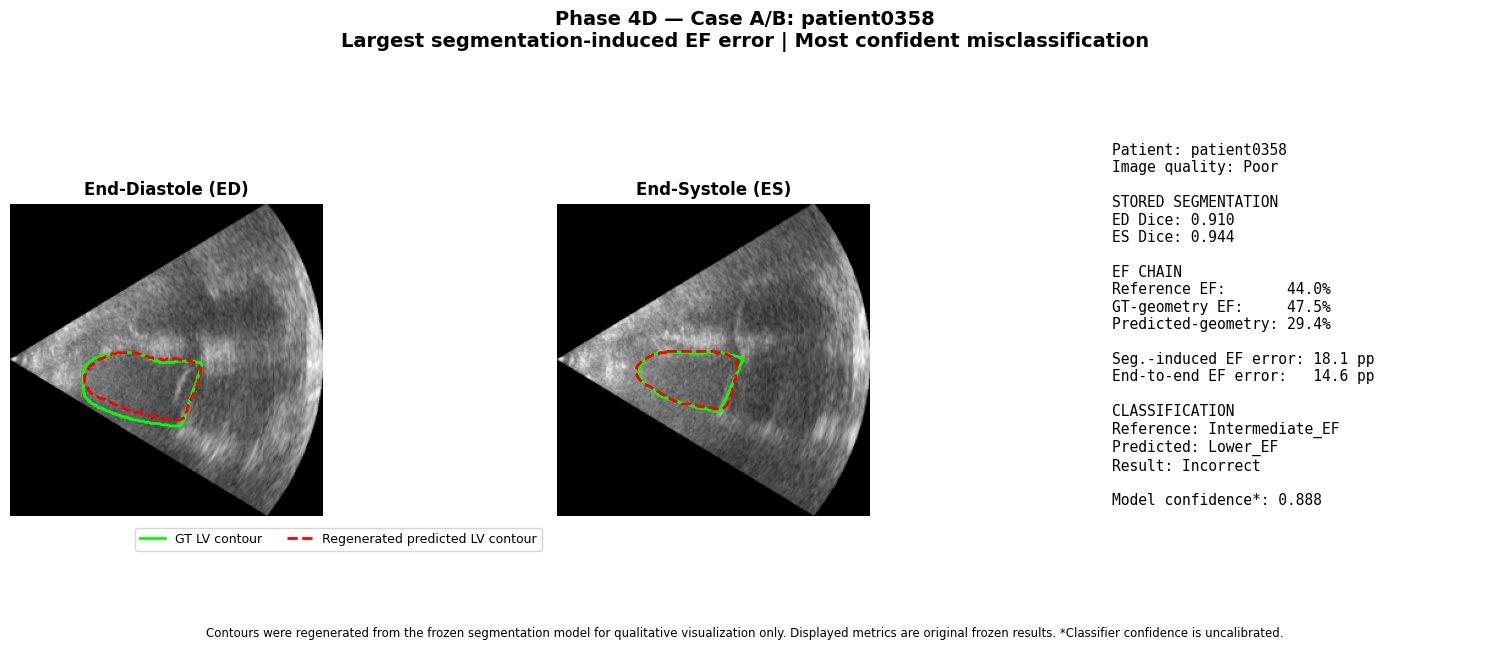

✓ Saved: phase4D_case_A_B_patient0358.png


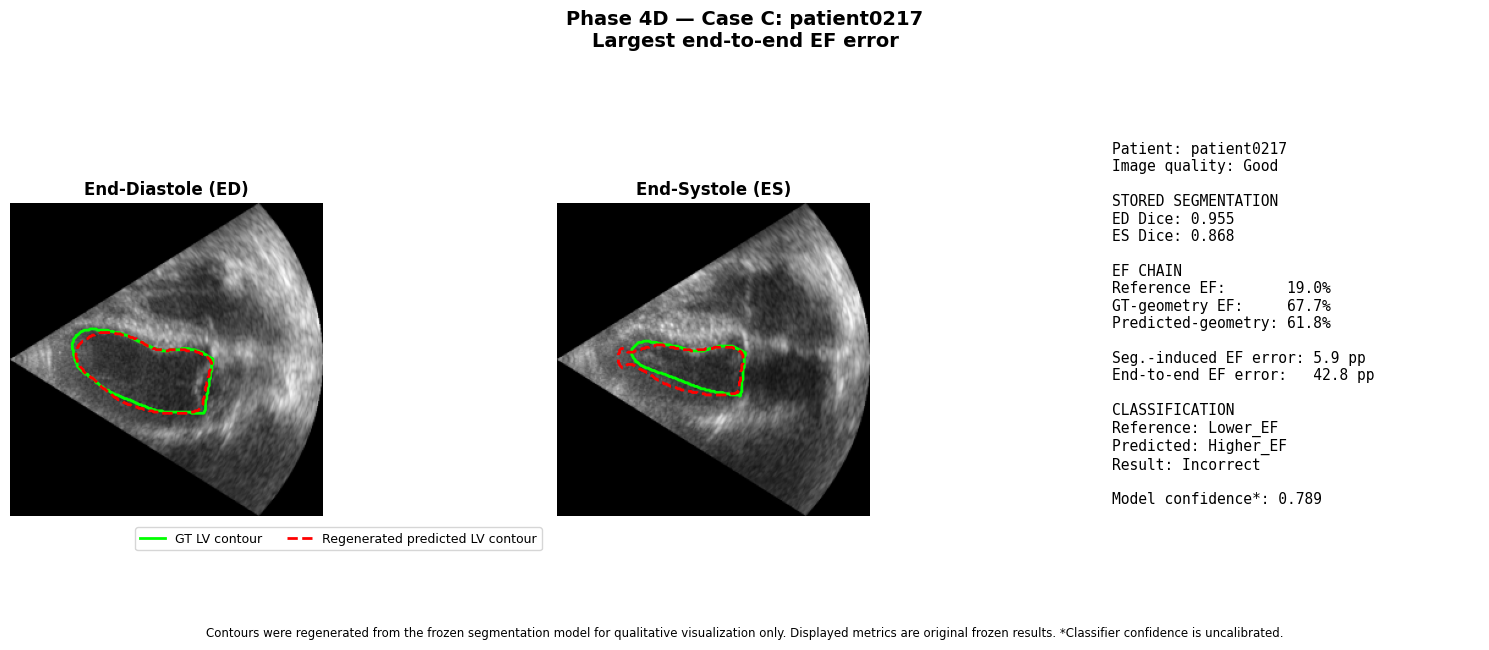

✓ Saved: phase4D_case_C_patient0217.png


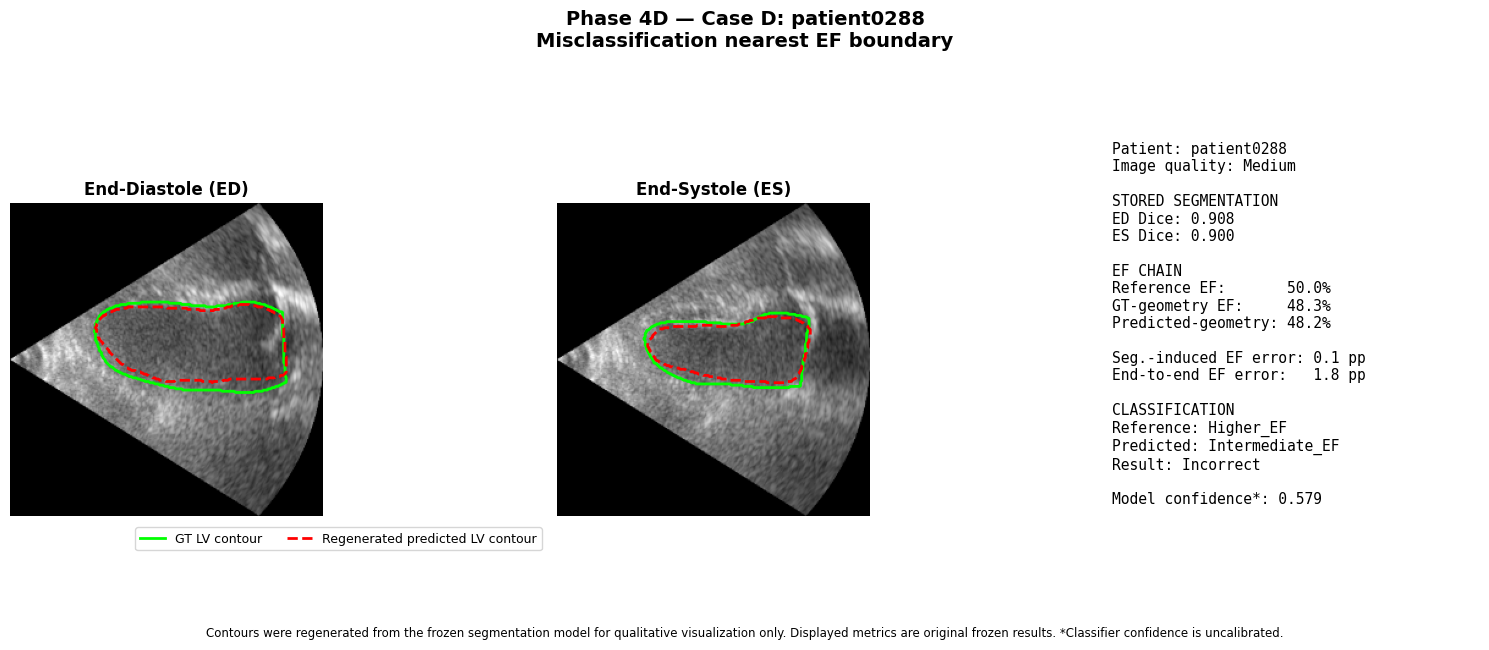

✓ Saved: phase4D_case_D_patient0288.png


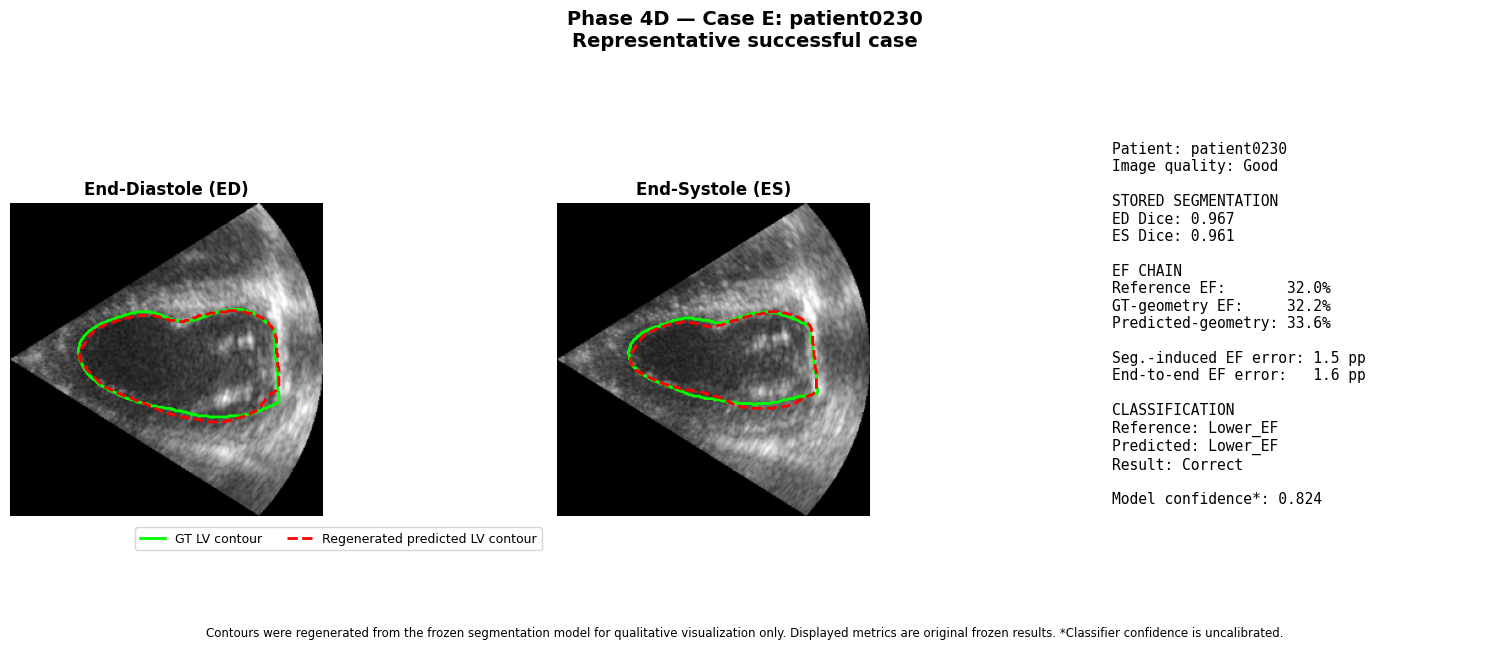

✓ Saved: phase4D_case_E_patient0230.png

FINAL REPRESENTATIVE CASE FIGURES
✓ phase4D_case_A_B_patient0358.png
✓ phase4D_case_C_patient0217.png
✓ phase4D_case_D_patient0288.png
✓ phase4D_case_E_patient0230.png

✓ All 4 unique representative patient figures generated.


In [ ]:
# ================================================================
# PHASE 4D — CELL 19
# GENERATE FINAL REPRESENTATIVE CASE FIGURES
# ================================================================

PHASE4D_FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


saved_case_figures = []


for patient_id in selected_patient_ids:

    # -----------------------------------------------------------
    # IDENTIFY CASE ROLE(S)
    # -----------------------------------------------------------

    patient_case_labels = (
        phase4D_selection_df.loc[
            phase4D_selection_df["patient_id"] == patient_id,
            "case_label"
        ]
        .tolist()
    )


    patient_criteria = (
        phase4D_selection_df.loc[
            phase4D_selection_df["patient_id"] == patient_id,
            "selection_criterion"
        ]
        .tolist()
    )


    # Display version: A/B
    case_label_text = "/".join(
        patient_case_labels
    )


    # Filename-safe version: A_B
    safe_case_label = "_".join(
        patient_case_labels
    )


    # -----------------------------------------------------------
    # CREATE FIGURE
    # -----------------------------------------------------------

    fig = plt.figure(
        figsize=(15, 6.5)
    )


    grid = fig.add_gridspec(
        1,
        3,
        width_ratios=[
            1,
            1,
            1.20
        ]
    )


    ax_ED = fig.add_subplot(
        grid[0, 0]
    )

    ax_ES = fig.add_subplot(
        grid[0, 1]
    )

    ax_text = fig.add_subplot(
        grid[0, 2]
    )


    # -----------------------------------------------------------
    # ED IMAGE
    # -----------------------------------------------------------

    show_contour_overlay(

        ax_ED,

        visual_case_data[
            patient_id
        ]["ED"]["image"],

        visual_case_data[
            patient_id
        ]["ED"]["gt_mask"],

        visual_case_data[
            patient_id
        ]["ED"]["pred_mask"],

        "End-Diastole (ED)"
    )


    # -----------------------------------------------------------
    # ES IMAGE
    # -----------------------------------------------------------

    show_contour_overlay(

        ax_ES,

        visual_case_data[
            patient_id
        ]["ES"]["image"],

        visual_case_data[
            patient_id
        ]["ES"]["gt_mask"],

        visual_case_data[
            patient_id
        ]["ES"]["pred_mask"],

        "End-Systole (ES)"
    )


    # -----------------------------------------------------------
    # LEGEND
    # -----------------------------------------------------------

    ax_ED.legend(
        handles=contour_legend_elements,
        loc="lower center",
        bbox_to_anchor=(1.05, -0.13),
        ncol=2,
        fontsize=9,
        frameon=True
    )


    # -----------------------------------------------------------
    # FROZEN METRICS PANEL
    # -----------------------------------------------------------

    ax_text.axis(
        "off"
    )


    ax_text.text(
        0.02,
        0.98,
        case_annotations[
            patient_id
        ],
        va="top",
        ha="left",
        fontsize=10.5,
        family="monospace"
    )


    # -----------------------------------------------------------
    # CASE-SELECTION CRITERION
    # -----------------------------------------------------------

    criterion_text = " | ".join(
        patient_criteria
    )


    fig.suptitle(
        (
            f"Phase 4D — Case {case_label_text}: "
            f"{patient_id}\n"
            f"{criterion_text}"
        ),
        fontsize=14,
        fontweight="bold"
    )


    # -----------------------------------------------------------
    # PROVENANCE FOOTNOTE
    # -----------------------------------------------------------

    fig.text(
        0.5,
        0.015,
        (
            "Contours were regenerated from the frozen segmentation "
            "model for qualitative visualization only. "
            "Displayed metrics are original frozen results. "
            "*Classifier confidence is uncalibrated."
        ),
        ha="center",
        fontsize=8.5
    )


    plt.tight_layout(
        rect=[
            0,
            0.07,
            1,
            0.90
        ]
    )


    # -----------------------------------------------------------
    # SAFE OUTPUT PATH
    # -----------------------------------------------------------

    output_path = (
        PHASE4D_FIGURES_DIR
        / (
            f"phase4D_case_"
            f"{safe_case_label}_"
            f"{patient_id}.png"
        )
    )


    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()

    plt.close(
        fig
    )


    saved_case_figures.append(
        output_path
    )


    print(
        "✓ Saved:",
        output_path.name
    )


# ---------------------------------------------------------------
# VERIFY OUTPUTS
# ---------------------------------------------------------------

print("\n" + "=" * 80)
print("FINAL REPRESENTATIVE CASE FIGURES")
print("=" * 80)


for path in saved_case_figures:

    assert path.exists()

    print(
        "✓",
        path.name
    )


assert len(saved_case_figures) == 4


print(
    "\n✓ All 4 unique representative patient figures generated."
)

In [ ]:
# ================================================================
# PHASE 4D — CELL 20
# FINAL REPRESENTATIVE CASE INTERPRETATION TABLE
# ================================================================

case_interpretation_records = [

    # -----------------------------------------------------------
    # CASE A/B — SEGMENTATION PROPAGATION + CONFIDENT ERROR
    # -----------------------------------------------------------

    {
        "case": "A/B",

        "patient_id": "patient0358",

        "case_role": (
            "Largest segmentation-induced EF error; "
            "most confident misclassification"
        ),

        "observed_pattern": (
            "Segmentation-associated EF propagation error "
            "with confidently incorrect classification"
        ),

        "interpretation": (
            "GT-geometry EF was 47.49%, whereas predicted-geometry "
            "EF was 29.44%, corresponding to an 18.06 pp "
            "segmentation-induced EF difference. The final EF-band "
            "prediction was incorrect despite a high uncalibrated "
            "classifier confidence score of 0.888."
        )
    },


    # -----------------------------------------------------------
    # CASE C — GEOMETRY / REFERENCE DISAGREEMENT
    # -----------------------------------------------------------

    {
        "case": "C",

        "patient_id": "patient0217",

        "case_role": (
            "Largest end-to-end EF disagreement"
        ),

        "observed_pattern": (
            "Large reference-versus-GT-geometry EF disagreement"
        ),

        "interpretation": (
            "Reference EF was 19.00%, whereas EF derived from "
            "GT-mask geometry was 67.67% and predicted-geometry EF "
            "was 61.79%. Therefore, much of the 42.79 pp end-to-end "
            "disagreement was already present between the reference "
            "EF and the 2D GT-mask-derived geometry rather than being "
            "introduced by segmentation alone."
        )
    },


    # -----------------------------------------------------------
    # CASE D — EF-BOUNDARY SENSITIVITY
    # -----------------------------------------------------------

    {
        "case": "D",

        "patient_id": "patient0288",

        "case_role": (
            "Misclassification nearest an EF-band boundary"
        ),

        "observed_pattern": (
            "EF-band boundary sensitivity"
        ),

        "interpretation": (
            "Reference EF was exactly 50.00%, while predicted-geometry "
            "EF was 48.25%. Although the end-to-end EF disagreement "
            "was only 1.75 pp, it crossed the predefined 50% boundary "
            "and changed the EF-band assignment from Higher_EF to "
            "Intermediate_EF."
        )
    },


    # -----------------------------------------------------------
    # CASE E — SUCCESSFUL COMPARISON
    # -----------------------------------------------------------

    {
        "case": "E",

        "patient_id": "patient0230",

        "case_role": (
            "Representative successful pipeline case"
        ),

        "observed_pattern": (
            "Strong segmentation and small downstream disagreement"
        ),

        "interpretation": (
            "Stored ED and ES Dice were 0.967 and 0.961, respectively. "
            "Segmentation-induced EF error was 1.48 pp and end-to-end "
            "EF error was 1.65 pp. The final Lower_EF classification "
            "was correct."
        )
    }
]


phase4D_case_interpretation_df = pd.DataFrame(
    case_interpretation_records
)


print("=" * 100)
print("PHASE 4D — REPRESENTATIVE CASE INTERPRETATIONS")
print("=" * 100)


display(
    phase4D_case_interpretation_df
)


# ---------------------------------------------------------------
# SAVE
# ---------------------------------------------------------------

PHASE4D_CASE_INTERPRETATION_PATH = (
    PHASE4D_TABLES_DIR
    / "phase4D_case_interpretations.csv"
)


phase4D_case_interpretation_df.to_csv(
    PHASE4D_CASE_INTERPRETATION_PATH,
    index=False
)


assert PHASE4D_CASE_INTERPRETATION_PATH.exists()


print(
    "\n✓ Representative case interpretation table saved."
)

print(
    PHASE4D_CASE_INTERPRETATION_PATH
)

PHASE 4D — REPRESENTATIVE CASE INTERPRETATIONS


,case,patient_id,case_role,observed_pattern,interpretation
0,A/B,patient0358,Largest segmentation-induced EF error; most co...,Segmentation-associated EF propagation error w...,"GT-geometry EF was 47.49%, whereas predicted-g..."
1,C,patient0217,Largest end-to-end EF disagreement,Large reference-versus-GT-geometry EF disagree...,"Reference EF was 19.00%, whereas EF derived fr..."
2,D,patient0288,Misclassification nearest an EF-band boundary,EF-band boundary sensitivity,"Reference EF was exactly 50.00%, while predict..."
3,E,patient0230,Representative successful pipeline case,Strong segmentation and small downstream disag...,"Stored ED and ES Dice were 0.967 and 0.961, re..."



✓ Representative case interpretation table saved.
/content/drive/MyDrive/CAMUS_FINAL/phase4_robustness/phase4D_representative_failure_cases/tables/phase4D_case_interpretations.csv


In [ ]:
# ================================================================
# PHASE 4D — CELL 21
# FINAL RECORD AND FREEZE
# ================================================================

phase4D_final_record = {

    "phase":
        "Phase 4D",

    "title":
        "Representative Success and Failure Case Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "purpose": (
        "Illustrate quantitatively predefined representative success "
        "and failure patterns of the frozen end-to-end pipeline at "
        "the patient level."
    ),

    "analysis_type":
        "Descriptive representative-case analysis",

    "pipeline_modified":
        False,

    "case_selection": {

        "selection_defined_before_visual_inspection":
            True,

        "visual_cherry_picking":
            False,

        "number_of_selection_criteria":
            5,

        "number_of_unique_patients":
            int(
                phase4D_selection_df[
                    "patient_id"
                ].nunique()
            ),

        "duplicate_selection_retained":
            True
    },


    "selected_cases": {

        "A_B": {
            "patient_id":
                "patient0358",

            "role": (
                "Largest segmentation-induced EF error and "
                "most confident misclassification"
            )
        },

        "C": {
            "patient_id":
                "patient0217",

            "role":
                "Largest end-to-end EF disagreement"
        },

        "D": {
            "patient_id":
                "patient0288",

            "role":
                "Misclassification nearest EF-band boundary"
        },

        "E": {
            "patient_id":
                "patient0230",

            "role":
                "Representative successful pipeline case"
        }
    },


    "visualization_provenance": {

        "historical_prediction_masks_retained":
            False,

        "masks_regenerated_from_frozen_model":
            True,

        "regenerated_masks_used_for":
            "Qualitative visualization only",

        "maximum_absolute_dice_reproduction_difference":
            float(max_difference),

        "quantitative_results_source":
            "Original frozen Phase 1-4 analysis tables",

        "new_quantitative_metrics_from_regenerated_masks":
            False
    },


    "main_findings": [

        (
            "A large segmentation-associated EF propagation error "
            "can coincide with an incorrect EF-band prediction even "
            "when classifier confidence is high."
        ),

        (
            "Large end-to-end EF disagreement may arise substantially "
            "from disagreement between reference EF and the selected "
            "2D geometry-based measurement method rather than from "
            "segmentation alone."
        ),

        (
            "Small continuous EF differences can alter categorical "
            "EF-band assignment when the reference lies near a "
            "predefined class boundary."
        ),

        (
            "A representative successful case showed that strong "
            "segmentation, small quantitative disagreement, and correct "
            "classification can align within the frozen pipeline."
        )
    ],


    "limitations": [

        (
            "Representative cases are illustrative and do not estimate "
            "the prevalence of each failure mechanism."
        ),

        (
            "Historical prediction masks were not retained; regenerated "
            "masks are therefore restricted to qualitative visualization."
        ),

        (
            "A small discrepancy remained between regenerated masks and "
            "stored historical Dice metrics."
        ),

        (
            "The exact implementation-level source of the small "
            "reproduction discrepancy was not recoverable from the "
            "retained experiment records."
        ),

        (
            "Observed upstream-downstream error associations should not "
            "be interpreted as proof of causality."
        ),

        (
            "Classifier confidence scores are uncalibrated and should "
            "not be interpreted as calibrated probabilities or "
            "patient-level reliability guarantees."
        )
    ]
}


# ---------------------------------------------------------------
# SAVE FINAL RECORD
# ---------------------------------------------------------------

PHASE4D_FINAL_RECORD_PATH = (
    PHASE4D_CONFIGS_DIR
    / "phase4D_final_record.json"
)


with open(
    PHASE4D_FINAL_RECORD_PATH,
    "w"
) as file:

    json.dump(
        phase4D_final_record,
        file,
        indent=4
    )


# ---------------------------------------------------------------
# PHASE COMPLETION MARKER
# ---------------------------------------------------------------

phase4D_completion_record = {

    "phase":
        "Phase 4D",

    "title":
        "Representative Success and Failure Case Analysis",

    "status":
        "COMPLETE_AND_FROZEN",

    "pipeline_modified":
        False,

    "phase4_robustness_complete":
        True,

    "next_phase":
        "Phase 5 — Assistive Application / System Integration"
}


PHASE4D_COMPLETE_PATH = (
    PHASE4D_DIR
    / "PHASE4D_COMPLETE.json"
)


with open(
    PHASE4D_COMPLETE_PATH,
    "w"
) as file:

    json.dump(
        phase4D_completion_record,
        file,
        indent=4
    )


# ---------------------------------------------------------------
# FINAL VERIFICATION
# ---------------------------------------------------------------

assert PHASE4D_FINAL_RECORD_PATH.exists()
assert PHASE4D_COMPLETE_PATH.exists()
assert PHASE4D_CASE_INTERPRETATION_PATH.exists()

assert len(saved_case_figures) == 4

for figure_path in saved_case_figures:
    assert figure_path.exists()


print("=" * 90)
print("PHASE 4D — COMPLETE AND FROZEN")
print("=" * 90)

print(
    "\n✓ Case selection was quantitatively predefined."
)

print(
    "✓ 5 selection criteria retained."
)

print(
    "✓ 4 unique representative patients visualized."
)

print(
    "✓ Duplicate A/B selection retained without replacement."
)

print(
    "✓ Original frozen quantitative metrics preserved."
)

print(
    "✓ Regenerated masks restricted to qualitative visualization."
)

print(
    "✓ No model retraining, tuning, calibration, or pipeline modification."
)

print(
    "✓ Final Phase 4D record saved."
)

print("\n" + "=" * 90)
print("PHASE 4 — ROBUSTNESS, UNCERTAINTY & FAILURE ANALYSIS COMPLETE")
print("=" * 90)

print(
    "\nPhase 4A: End-to-End Error Propagation       ✓"
)

print(
    "Phase 4B: Confidence & Uncertainty           ✓"
)

print(
    "Phase 4C: Image Quality & Failure Subgroups  ✓"
)

print(
    "Phase 4D: Representative Case Analysis       ✓"
)

print(
    "\nNext phase:"
)

print(
    "Phase 5 — Assistive Application / System Integration"
)

PHASE 4D — COMPLETE AND FROZEN

✓ Case selection was quantitatively predefined.
✓ 5 selection criteria retained.
✓ 4 unique representative patients visualized.
✓ Duplicate A/B selection retained without replacement.
✓ Original frozen quantitative metrics preserved.
✓ Regenerated masks restricted to qualitative visualization.
✓ No model retraining, tuning, calibration, or pipeline modification.
✓ Final Phase 4D record saved.

PHASE 4 — ROBUSTNESS, UNCERTAINTY & FAILURE ANALYSIS COMPLETE

Phase 4A: End-to-End Error Propagation       ✓
Phase 4B: Confidence & Uncertainty           ✓
Phase 4C: Image Quality & Failure Subgroups  ✓
Phase 4D: Representative Case Analysis       ✓

Next phase:
Phase 5 — Assistive Application / System Integration
